# FLOPs de inferencia de PosFormer en GPU

Estima exclusivamente los FLOPs de inferencia de **PosFormer** sobre CROHME 2014 mediante `torch.profiler`. Este notebook no mide ni reporta latencia.

> Los FLOPs son una estimación para los operadores que reconoce PyTorch; no representan necesariamente todas las operaciones de la búsqueda.

In [1]:
from pathlib import Path
import gc, json, os, platform, sys
os.environ.setdefault('KINETO_LOG_LEVEL', '5')

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

def find_project_root():
    for candidate in [Path.cwd(), *Path.cwd().parents, Path.cwd() / '..', Path.cwd() / '../..']:
        candidate = candidate.resolve()
        if (candidate / 'PosFormer').is_dir() and (candidate / 'data').is_dir():
            return candidate
    raise FileNotFoundError('No se encontró la raíz con PosFormer/ y data/.')

ROOT = find_project_root()
POS_ROOT = ROOT / 'PosFormer'
RESULTS_DIR = ROOT / 'Cascada' / '01_seleccion' / 'resultados'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device('cuda:0')
assert torch.cuda.is_available(), 'CUDA no está disponible.'
print('Raíz   :', ROOT)
print('GPU    :', torch.cuda.get_device_name(0))
print('PyTorch:', torch.__version__)

Raíz   : C:\Users\novac\Documents\Unidad\Documentos\IPN\Trabajo_terminal\Programas
GPU    : NVIDIA GeForce RTX 4050 Laptop GPU
PyTorch: 2.0.1+cu118


## Carga del modelo y del checkpoint

In [2]:
sys.path.insert(0, str(POS_ROOT))
from Pos_Former.lit_posformer import LitPosFormer
from Pos_Former.datamodule.transforms import ScaleToLimitRange

checkpoints = sorted((POS_ROOT / 'lightning_logs' / 'version_0' / 'checkpoints').glob('*.ckpt'))
if not checkpoints:
    raise FileNotFoundError('No se encontró un checkpoint de PosFormer.')
checkpoint = next((path for path in checkpoints if path.name == 'best.ckpt'), checkpoints[0])
model = LitPosFormer.load_from_checkpoint(str(checkpoint), map_location='cpu')
model = model.to(DEVICE).eval().requires_grad_(False)
torch.cuda.synchronize()
print('Checkpoint:', checkpoint)

c:\Users\novac\Documents\Unidad\Documentos\IPN\Trabajo_terminal\Programas\.venv-hmer-gpu\lib\site-packages\pytorch_lightning\utilities\migration\migration.py:203: PossibleUserWarning: You have multiple `ModelCheckpoint` callback states in this checkpoint, but we found state keys that would end up colliding with each other after an upgrade, which means we can't differentiate which of your checkpoint callbacks needs which states. At least one of your `ModelCheckpoint` callbacks will not be able to reload the state.
  rank_zero_warn(
Lightning automatically upgraded your loaded checkpoint from v1.4.9 to v2.0.9. To apply the upgrade to your files permanently, run `python -m pytorch_lightning.utilities.upgrade_checkpoint --file C:\Users\novac\Documents\Unidad\Documentos\IPN\Trabajo_terminal\Programas\PosFormer\lightning_logs\version_0\checkpoints\best.ckpt`


Checkpoint: C:\Users\novac\Documents\Unidad\Documentos\IPN\Trabajo_terminal\Programas\PosFormer\lightning_logs\version_0\checkpoints\best.ckpt


In [3]:
scale_transform = ScaleToLimitRange(w_lo=16, w_hi=1024, h_lo=16, h_hi=256)

def prepare_image(path):
    image = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if image is None:
        raise FileNotFoundError(path)
    original_h, original_w = image.shape
    transformed = scale_transform(image)
    tensor = torch.from_numpy(transformed.copy()).float().div_(255).unsqueeze(0).unsqueeze(0)
    _, _, height, width = tensor.shape
    mask = torch.zeros((1, height, width), dtype=torch.bool)
    resized = (original_h, original_w) != (height, width)
    return tensor.to(DEVICE), mask.to(DEVICE), (original_h, original_w), (height, width), resized

def estimate_flops(image, mask):
    with torch.profiler.profile(
        activities=[torch.profiler.ProfilerActivity.CPU],
        record_shapes=True,
        with_flops=True,
    ) as profiler:
        with torch.inference_mode():
            output = model.approximate_joint_search(image, mask)
        torch.cuda.synchronize()
    estimated_flops = sum(event.flops or 0 for event in profiler.key_averages())
    del output
    return int(estimated_flops)

## Configuración y calentamiento

`MAX_SAMPLES = None` procesa toda la partición. El calentamiento usa la transformación oficial y se realiza sin perfilador.

In [4]:
YEAR = '2014'
MAX_SAMPLES = None
WARMUP_RUNS = 3
PROGRESS_EVERY = 25

split_dir = ROOT / 'data' / 'Modelo2' / YEAR
samples = []
for line in (split_dir / 'caption.txt').read_text(encoding='utf-8').splitlines():
    parts = line.strip().split()
    if parts:
        sample_id = parts[0][:-4] if parts[0].endswith('.jpg') else parts[0]
        samples.append(sample_id)
if MAX_SAMPLES is not None:
    samples = samples[:MAX_SAMPLES]
if not samples:
    raise RuntimeError('No hay muestras para evaluar.')

print(f'Muestras seleccionadas: {len(samples)} | CROHME {YEAR}')
warm_image, warm_mask, _, _, _ = prepare_image(split_dir / 'img' / f'{samples[0]}.bmp')
with torch.inference_mode():
    for _ in range(WARMUP_RUNS):
        warm_output = model.approximate_joint_search(warm_image, warm_mask)
        torch.cuda.synchronize()
        del warm_output
del warm_image, warm_mask
gc.collect()
torch.cuda.synchronize()
print(f'Warm-up terminado: {WARMUP_RUNS} ejecuciones.')

Muestras seleccionadas: 986 | CROHME 2014
Warm-up terminado: 3 ejecuciones.


## Estimación de FLOPs

Se ejecuta una búsqueda perfilada por imagen. No se utiliza ningún cronómetro.

In [5]:
rows = []
for index, sample_id in enumerate(samples, start=1):
    path = split_dir / 'img' / f'{sample_id}.bmp'
    row = {
        'index': index, 'sample_id': sample_id, 'image_file': path.name,
        'status': 'ok', 'error': '',
    }
    try:
        image, mask, (height, width), (model_height, model_width), resized = prepare_image(path)
        estimated_flops = estimate_flops(image, mask)
        row.update({
            'height': height, 'width': width,
            'model_height': model_height, 'model_width': model_width,
            'resized': int(resized),
            'estimated_flops': estimated_flops,
            'estimated_gflops': estimated_flops / 1e9,
        })
        del image, mask
    except Exception as exc:
        row.update({
            'status': 'error', 'error': f'{type(exc).__name__}: {exc}',
            'estimated_flops': np.nan, 'estimated_gflops': np.nan,
        })
        if 'out of memory' in str(exc).lower():
            rows.append(row)
            raise
    rows.append(row)
    gc.collect()
    if index == 1 or index % PROGRESS_EVERY == 0 or index == len(samples):
        valid_now = [item['estimated_gflops'] for item in rows if item['status'] == 'ok']
        print(f'{index:4d}/{len(samples)} | válidas={len(valid_now):4d} | GFLOPs media={np.mean(valid_now):.2f}')

   1/986 | válidas=   1 | GFLOPs media=3.10
  25/986 | válidas=  25 | GFLOPs media=132.63
  50/986 | válidas=  50 | GFLOPs media=69.42
  75/986 | válidas=  75 | GFLOPs media=88.42
 100/986 | válidas= 100 | GFLOPs media=68.24
 125/986 | válidas= 125 | GFLOPs media=56.10
 150/986 | válidas= 150 | GFLOPs media=48.36
 175/986 | válidas= 175 | GFLOPs media=43.37
 200/986 | válidas= 200 | GFLOPs media=39.42
 225/986 | válidas= 225 | GFLOPs media=36.83
 250/986 | válidas= 250 | GFLOPs media=34.86
 275/986 | válidas= 275 | GFLOPs media=33.62
 300/986 | válidas= 300 | GFLOPs media=33.73
 325/986 | válidas= 325 | GFLOPs media=32.74
 350/986 | válidas= 350 | GFLOPs media=32.44
 375/986 | válidas= 375 | GFLOPs media=33.62
 400/986 | válidas= 400 | GFLOPs media=34.81
 425/986 | válidas= 425 | GFLOPs media=35.96
 450/986 | válidas= 450 | GFLOPs media=36.94
 475/986 | válidas= 475 | GFLOPs media=38.23
 500/986 | válidas= 500 | GFLOPs media=39.99
 525/986 | válidas= 525 | GFLOPs media=42.57
 550/986 |

## Resumen y visualización

,valor
model,PosFormer
metric,estimated FLOPs
dataset,CROHME 2014
samples_requested,986
samples_valid,986
errors,0
estimated_flops_mean,219536757427.312378
estimated_flops_median,69109997399.0
estimated_flops_p95,764985701833.5
estimated_flops_p99,1859614449796.998535


CSV    : C:\Users\novac\Documents\Unidad\Documentos\IPN\Trabajo_terminal\Programas\Cascada\01_seleccion\resultados\benchmark_posformer_flops_crohme_2014.csv
Resumen: C:\Users\novac\Documents\Unidad\Documentos\IPN\Trabajo_terminal\Programas\Cascada\01_seleccion\resultados\resumen_posformer_flops_crohme_2014.json


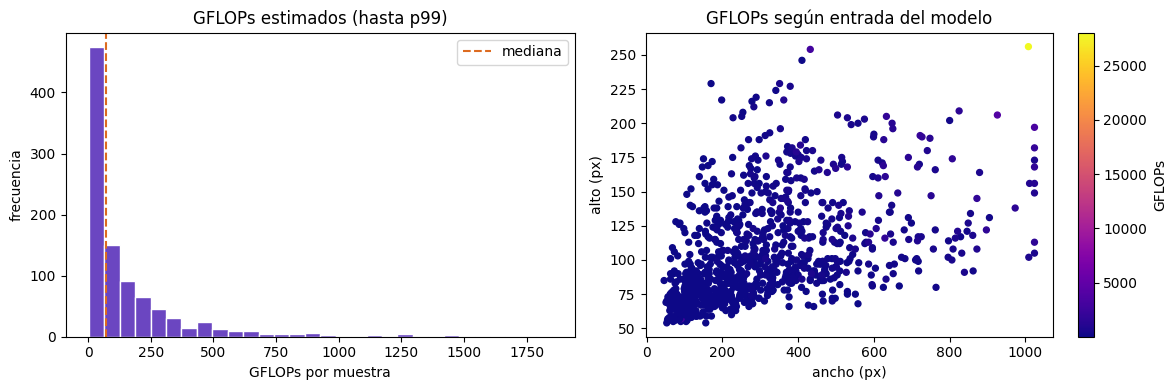

Gráfica: C:\Users\novac\Documents\Unidad\Documentos\IPN\Trabajo_terminal\Programas\Cascada\01_seleccion\resultados\benchmark_posformer_flops_crohme_2014.png


In [6]:
results = pd.DataFrame(rows)
valid = results.loc[results['status'] == 'ok'].copy()
if valid.empty:
    raise RuntimeError('No hubo estimaciones válidas.')
flops = valid['estimated_flops'].to_numpy(dtype=np.float64)
summary = {
    'model': 'PosFormer',
    'metric': 'estimated FLOPs',
    'dataset': f'CROHME {YEAR}',
    'samples_requested': len(samples),
    'samples_valid': len(valid),
    'errors': int((results['status'] != 'ok').sum()),
    'estimated_flops_mean': float(np.mean(flops)),
    'estimated_flops_median': float(np.median(flops)),
    'estimated_flops_p95': float(np.percentile(flops, 95)),
    'estimated_flops_p99': float(np.percentile(flops, 99)),
    'estimated_flops_min': float(np.min(flops)),
    'estimated_flops_max': float(np.max(flops)),
    'estimated_gflops_mean': float(np.mean(flops) / 1e9),
    'estimated_gflops_median': float(np.median(flops) / 1e9),
    'estimated_gflops_p95': float(np.percentile(flops, 95) / 1e9),
    'estimated_gflops_p99': float(np.percentile(flops, 99) / 1e9),
    'estimated_gflops_min': float(np.min(flops) / 1e9),
    'estimated_gflops_max': float(np.max(flops) / 1e9),
    'estimated_total_tflops': float(np.sum(flops) / 1e12),
    'resized_samples': int(valid['resized'].sum()),
    'gpu': torch.cuda.get_device_name(0),
    'python': platform.python_version(),
    'pytorch': torch.__version__,
    'cuda': torch.version.cuda,
    'warmup_runs': WARMUP_RUNS,
    'flops_scope': 'Estimación de torch.profiler para los operadores soportados; una búsqueda perfilada por imagen.',
}

csv_path = RESULTS_DIR / f'benchmark_posformer_flops_crohme_{YEAR}.csv'
json_path = RESULTS_DIR / f'resumen_posformer_flops_crohme_{YEAR}.json'
results.to_csv(csv_path, index=False, encoding='utf-8')
json_path.write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
display(pd.DataFrame([summary]).T.rename(columns={0: 'valor'}))
print('CSV    :', csv_path)
print('Resumen:', json_path)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
display_limit = np.percentile(valid['estimated_gflops'], 99)
axes[0].hist(valid.loc[valid['estimated_gflops'] <= display_limit, 'estimated_gflops'], bins=30, color='#6b46c1', edgecolor='white')
axes[0].axvline(summary['estimated_gflops_median'], color='#dd6b20', linestyle='--', label='mediana')
axes[0].set(title='GFLOPs estimados (hasta p99)', xlabel='GFLOPs por muestra', ylabel='frecuencia')
axes[0].legend()
scatter = axes[1].scatter(valid['model_width'], valid['model_height'], c=valid['estimated_gflops'], cmap='plasma', s=18)
axes[1].set(title='GFLOPs según entrada del modelo', xlabel='ancho (px)', ylabel='alto (px)')
fig.colorbar(scatter, ax=axes[1], label='GFLOPs')
fig.tight_layout()
plot_path = RESULTS_DIR / f'benchmark_posformer_flops_crohme_{YEAR}.png'
fig.savefig(plot_path, dpi=160, bbox_inches='tight')
plt.show()
print('Gráfica:', plot_path)

## Lectura de los resultados

- Cada muestra produce una única búsqueda bajo `torch.profiler`.
- `with_flops=True` solo contabiliza los operadores para los que PyTorch implementa estimación de FLOPs.
- El total en TFLOPs es la suma de las estimaciones de las muestras, no una tasa por segundo.
- `model_height` y `model_width` registran el tamaño posterior a la transformación oficial de PosFormer.
- No se calcula ni reporta latencia, porque la instrumentación del perfilador altera el tiempo de ejecución.